# PetroTwin data preparation and quality audit

Run this notebook **before** `notebooks/01_eda/01_fuel_market_eda.ipynb`. The existing `petrotwin.data.pipeline` is the one source-to-canonical cleaner; this notebook profiles its raw inputs and accepted outputs without changing either. It checks schema, missingness, duplicate keys, distributions, time coverage, row reconciliation, hashes, quarantine, and prior-date joins.

Outlier rules create review flags only. They do not delete, cap, or impute values. Missing values remain missing; source files and accepted run files are read-only here.

In [1]:
from IPython.display import display, Markdown
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

repo_candidates = [Path.cwd(), *Path.cwd().parents]
repo_root = next((path for path in repo_candidates if (path / 'data/processed/current.json').is_file()), None)
if repo_root is None:
    raise FileNotFoundError('Open this notebook from a PetroTwin repository checkout')
sys.path.insert(0, str(repo_root / 'src'))

from petrotwin.data.quality_audit import (
    annotation_coverage, column_profile, fuel_coverage, key_profile,
    load_bundle, make_quality_figures, quality_gates, source_inventory,
)

pd.set_option('display.max_columns', 40)
pd.set_option('display.max_rows', 120)
pd.set_option('display.width', 180)
bundle = load_bundle(repo_root)
print(f"Repository: {bundle['root']}")
print(f"Accepted run: {bundle['pointer']['run_id']} | schema: {bundle['pointer']['schema_version']}")
print(f"Published: {bundle['pointer']['published_at_utc']}")
print(f"Quality status: {bundle['quality']['publication_status']}")

Repository: E:\KHDL\Đồ án\PetroTwin-
Accepted run: 28b22922e761cb08a8d8 | schema: petrotwin-data-v3
Published: 2026-10-23T06:02:29.429696Z
Quality status: validated_with_quarantine


## 1. Raw-file inventory and schema profile

The inventory shows file size, shape, blank cells, exact repeated rows, and date coverage. The column profile reports data type, unique values, missing percentage, numeric quantiles, zero/negative counts, and Tukey 1.5×IQR review flags. IQR flags are not evidence that a source value is wrong.

In [2]:
display(source_inventory(bundle))
profile = column_profile(bundle)
display(profile)

,rows,columns,file_mb,blank_cells,blank_cell_pct,exact_duplicate_rows,date_min,date_max
source,,,,,,,,
Brent,2128,10,0.473,124,0.583,0,2018-08-22,2026-10-20
USD/VND,2400,10,0.508,0,0.000,0,2018-08-22,2026-10-22
Fuel prices,1454,12,0.222,16,0.092,0,2018-08-21,2026-10-22


dtype  rows  non_null  missing  missing_pct  distinct       min          q1   median          mean          std         q3  \
source      column                                                                                                                                                             
Brent       date                                    str  2128      2128        0        0.000      2128       NaN         NaN      NaN           NaN          NaN        NaN   
            product_name                            str  2128      2128        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            price_usd_per_barrel                float64  2128      2066       62        2.914      1748      9.12     64.2325     74.3     74.921839    19.825007     84.865   
            unit                                    str  2128      2128        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            source_url                              str  2128      2128        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            series_id                               str  2128      2128        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            publisher                               str  2128      2128        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            source_value                        float64  2128      2066       62        2.914      1748      9.12     64.2325     74.3     74.921839    19.825007     84.865   
            observation_status                      str  2128      2128        0        0.000         2       NaN         NaN      NaN           NaN          NaN        NaN   
            extracted_at_utc                        str  2128      2128        0        0.000         2       NaN         NaN      NaN           NaN          NaN        NaN   
USD/VND     date                                    str  2400      2400        0        0.000      2400       NaN         NaN      NaN           NaN          NaN        NaN   
            base_currency                           str  2400      2400        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            quote_currency                          str  2400      2400        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            rate_vnd_per_usd                      int64  2400      2400        0        0.000       940  22673.00  23146.0000  23289.0  23781.187917   824.138003  24259.000   
            unit                                    str  2400      2400        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            rate_type                               str  2400      2400        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            source_url                              str  2400      2400        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            source_attribution                      str  2400      2400        0        0.000         1       NaN         NaN      NaN           NaN          NaN        NaN   
            source_value                            str  2400      2400        0        0.000       940       NaN         NaN      NaN           NaN          NaN        NaN   
            extracted_at_utc                        str  2400      2400        0        0.000         2       NaN         NaN      NaN           NaN          NaN        NaN   
Fuel prices date                                    str  1454      1454        0        0.000       310       NaN         NaN      NaN           NaN          NaN        NaN   
  

## 2. Key integrity and cleaned-output coverage

Fuel records are irregular price-adjustment events, not daily observations. Product histories remain separate. This section checks raw and canonical keys, summarizes event gaps and price ranges by product, and shows how many fund annotations are confirmed versus unverified.

In [3]:
display(key_profile(bundle))
display(fuel_coverage(bundle))
display(annotation_coverage(bundle))

,key,rows,rows_with_missing_key,rows_in_repeated_keys,unique_key_count
table,,,,,
Raw Brent,date,2128,0,0,2128
Raw USD/VND,date,2400,0,0,2400
Raw fuel,"product_name, effective_date, effective_time",1454,0,0,1454
Canonical fuel,"product_id, effective_at_local, source_id, sna...",1390,0,0,1390
Canonical market,"series_id, observation_date, source_id, snapsh...",4528,0,0,4528
Canonical panel,"product_id, effective_at_local, target_snapsho...",1390,0,0,1390


,source_product_name,events,distinct_event_dates,first_event,last_event,median_gap_days,q1_gap_days,q3_gap_days,max_gap_days,price_min,price_median,price_max,missing_price_changes,missing_brent,missing_fx
product_id,,,,,,,,,,,,,,,
diesel_0001s_v,"Dầu DO 0,001S-V",119,119,2024-09-26,2026-10-22,7.0,7.0,7.0,11.0,17430.0,19360.0,44980.0,0,0,0
diesel_0005s_iv,"Dầu DO 0,005S-IV",10,10,2018-08-22,2019-01-01,15.0,15.0,15.0,16.0,14950.0,17920.0,18660.0,1,1,1
diesel_005s_ii,"Dầu DO 0,05S-II",310,310,2018-08-22,2026-10-22,7.0,7.0,15.0,21.0,9850.0,18980.0,44780.0,1,1,1
fuel_oil_35s,"Dầu FO 3,5%S",1,1,2024-05-30,2024-05-30,NaN,NaN,NaN,NaN,17530.0,17530.0,17530.0,0,0,0
fuel_oil_3s,Dầu FO 3%S,0,0,None,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0
gasoline_e10_ron95_iii,Xăng E10 RON 95-III,74,74,2025-07-31,2026-10-22,7.0,6.0,7.0,8.0,18460.0,21315.0,31420.0,0,0,0
gasoline_e5_ron92_ii,Xăng E5 RON 92-II,310,310,2018-08-22,2026-10-22,7.0,7.0,15.0,21.0,10940.0,20500.0,31300.0,1,1,1
gasoline_ron95_iii,Xăng RON 95-III,287,287,2018-08-22,2026-05-28,8.0,7.0,15.0,21.0,11630.0,21230.0,33840.0,1,1,1
gasoline_ron95_iv,Xăng RON 95-IV,10,10,2018-08-22,2019-01-01,15.0,15.0,15.0,16.0,17800.0,21315.0,22540.0,1,1,1


,count
label,
verified spending,130
verified no spending,435
unverified / missing,825


## 3. Raw → canonical → quarantine reconciliation

The pipeline's quality report distinguishes accepted canonical rows from row-level rejects. Brent's explicitly missing observations stay in the canonical table with `missing` status and NULL values; they are not counted as quarantine.

In [5]:
source_checks = bundle['quality']['source_checks']
reconciliation = pd.DataFrame([
    {'source': 'Brent', **source_checks['brent']},
    {'source': 'USD/VND', **source_checks['usd_vnd']},
    {'source': 'Fuel prices', **source_checks['fuel_prices']},
]).set_index('source')
display(reconciliation)
display(pd.DataFrame(bundle['manifest']['outputs']).T.rename_axis('output'))
display(bundle['processed']['quarantine']['reason_code'].value_counts(dropna=False).rename('rows').to_frame())

,distinct_dates,exact_duplicates_collapsed,first_observation_date,interval_days,last_observation_date,missing_values,quarantined_rows,rows_canonical,rows_read,schema_fingerprint_sha256,source_file,effective_24_00_normalized,effective_24_00_source_rows,missing_price_change_values,products,zero_prices_quarantined
source,,,,,,,,,,,,,,,,
Brent,2128.0,0,2018-08-22,"{'1': 1701, '3': 425, '5': 1}",2026-10-20,62.0,0,2128,2128,a877ec7fd26b406d2348bb3d4072551b4eb8a72d43dbd3...,brent_crude_prices.csv,NaN,NaN,NaN,NaN,NaN
USD/VND,2400.0,0,2018-08-22,"{'1': 1964, '2': 338, '3': 79, '4': 7, '5': 3,...",2026-10-22,0.0,0,2400,2400,c008654d0084f363a803e32e91732a6fedd1e2e459c332...,usd_vnd_rates.csv,NaN,NaN,NaN,NaN,NaN
Fuel prices,NaN,0,NaN,NaN,NaN,NaN,64,1390,1454,6e76862985400abc3be847831ba924a8b52bdfdde6825b...,data_price_petro.csv,131.0,161.0,8.0,{'diesel_0001s_v': {'canonical_first_effective...,64.0


,rows,sha256
output,,
fuel_market_panel.csv,1390,5650b6abf084f4ca9c44cc2f82525918fc200cedf492d6...
fuel_price_observation.csv,1390,726a4b8bf6dc19de52df46849204f335468848ffd78e76...
market_observation.csv,4528,df1abd0f14626053e36f700aebdbed94460ae91436302a...
quarantine.csv,64,400c991d6a34bdca6838dd72d1fe7722fba40b2e28b5ca...


,rows
reason_code,
domestic_zero_price_pending_source_confirmation,64


## 4. Quality gates

A FAIL blocks the handoff to EDA until investigated. WARN records a known limitation for the analysis. In particular, the accepted snapshot has zero-price FO exceptions pending source confirmation and unverified source reuse terms; these must remain visible in the project notes.

In [6]:
gates = quality_gates(bundle)
display(gates)
print('Failed checks:', int(gates['status'].eq('FAIL').sum()))
print('Warnings:', int(gates['status'].eq('WARN').sum()))

,status,detail
check,,
Source checksum: brent_crude_prices.csv,PASS,matches after Windows CRLF normalization
Source checksum: usd_vnd_rates.csv,PASS,matches after Windows CRLF normalization
Source checksum: data_price_petro.csv,PASS,matches after Windows CRLF normalization
Source checksum: manual/stabilization_fund_annotations.csv,PASS,matches after Windows CRLF normalization
Output manifest: fuel_market_panel.csv,PASS,rows 1390/1390; checksum match after Windows C...
Output manifest: fuel_price_observation.csv,PASS,rows 1390/1390; checksum match after Windows C...
Output manifest: market_observation.csv,PASS,rows 4528/4528; checksum match after Windows C...
Output manifest: quarantine.csv,PASS,rows 64/64; checksum match after Windows CRLF ...
Raw and canonical keys,PASS,No missing or repeated natural keys


Failed checks: 0
Warnings: 1


## 5. Diagnostic visualizations

These charts describe data completeness, ranges, and temporal coverage. They do not compare target values with Brent/FX or claim a predictive relationship; that belongs to EDA after this audit is reviewed.

### Row reconciliation

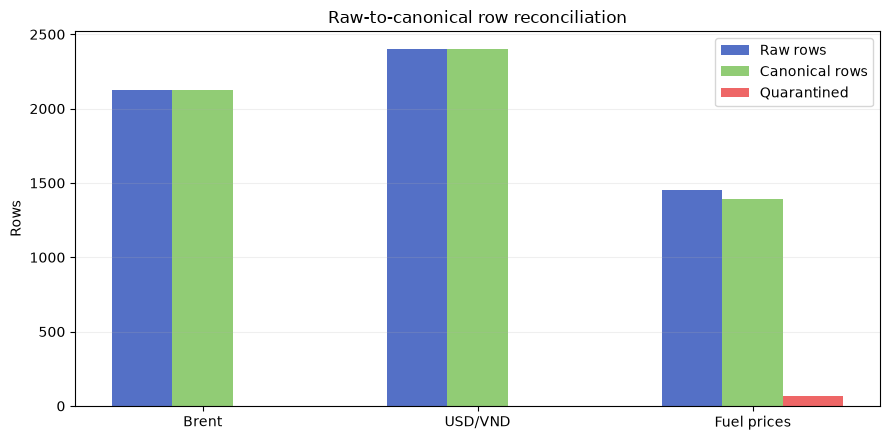

### Raw missingness

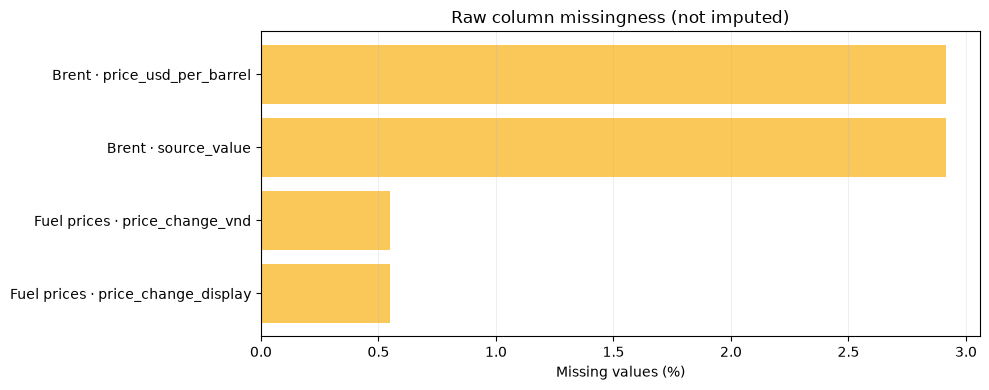

### Fuel price distributions

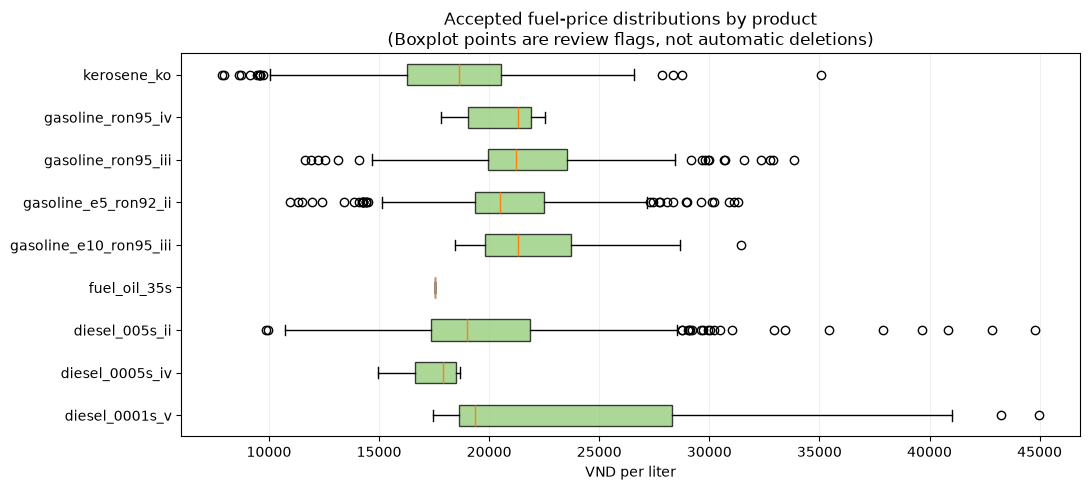

### Fuel coverage

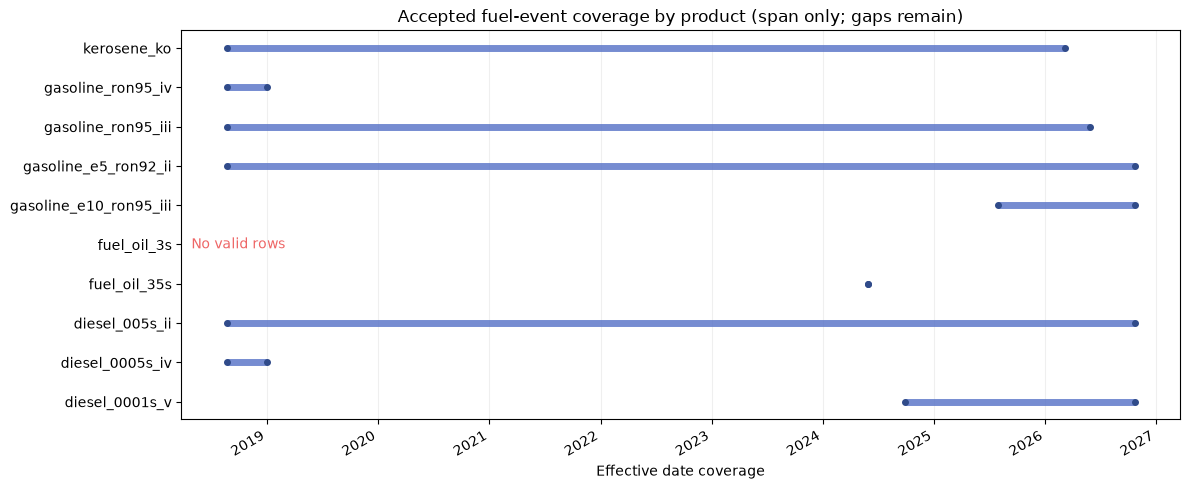

### Market interval diagnostics

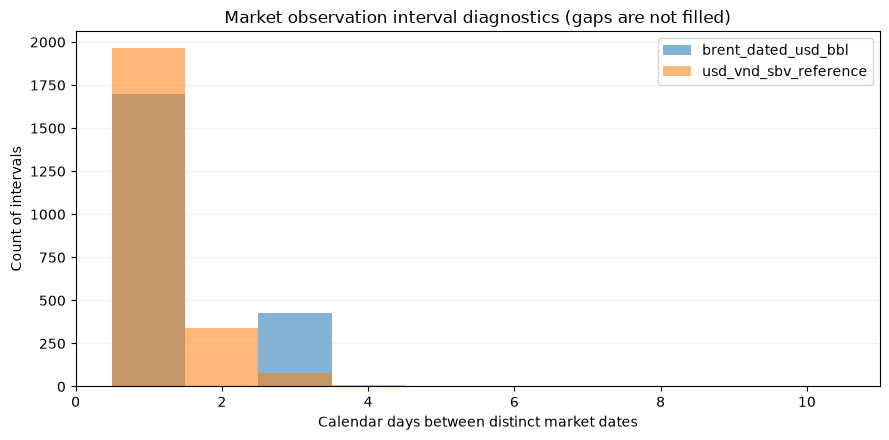

### IQR review flags

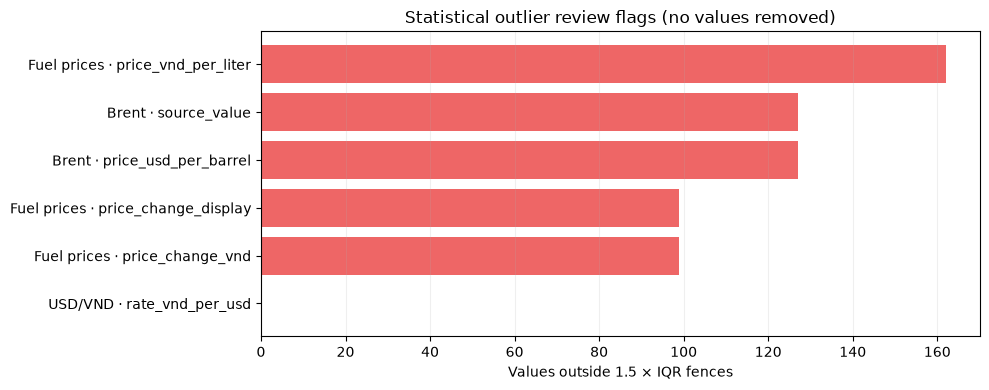

In [7]:
for title, figure in make_quality_figures(bundle):
    display(Markdown(f'### {title}'))
    display(figure)
    plt.close(figure)

## Preparation decisions to preserve

- Keep raw source CSVs immutable and use the pipeline-produced canonical run.
- Do not fill market gaps, carry prices forward, turn event data into daily rows, or replace NULL with zero.
- Keep the 64 zero-price FO records in quarantine until PVOIL confirms their meaning.
- Treat product/series history gaps as diagnostics; grades are not interchangeable.
- Review every IQR outlier against the source before proposing a correction.
- Record the run ID, quality warnings, and any unresolved source issues in the handoff.

**EDA handoff:** proceed to `01_fuel_market_eda.ipynb` only after all FAIL checks are resolved and the WARN items above are understood and documented.